<a href="https://colab.research.google.com/github/zinofiad824-cloud/-ppi-ml-learning/blob/main/iMDM2_MDMX_Comparison.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
%pip install -q biopython pandas numpy matplotlib

In [2]:

from Bio.PDB import PDBParser, Superimposer
from Bio.PDB.Polypeptide import is_aa
from Bio.SeqUtils import seq1
from Bio.Align import PairwiseAligner

from pathlib import Path
from urllib.request import urlretrieve

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:

project = Path("week02_mdm2_mdmx")

raw_folder = project / "data" / "raw"
processed_folder = project / "data" / "processed"
results_folder = project / "results"

for folder in [raw_folder, processed_folder, results_folder]:
    folder.mkdir(parents=True, exist_ok=True)

pdb_ids = ["1YCR", "3DAB"]

for pdb_id in pdb_ids:

    url = f"https://files.rcsb.org/download/{pdb_id}.pdb"
    destination = raw_folder / f"{pdb_id}.pdb"

    if not destination.exists():
        urlretrieve(url, destination)

    print("Ready:", destination)


Ready: week02_mdm2_mdmx/data/raw/1YCR.pdb
Ready: week02_mdm2_mdmx/data/raw/3DAB.pdb


In [4]:

parser = PDBParser(QUIET=True)

structures = {}

for pdb_id in pdb_ids:

    pdb_file = raw_folder / f"{pdb_id}.pdb"

    structures[pdb_id] = parser.get_structure(
        pdb_id,
        str(pdb_file)
    )

print("Structures loaded:", list(structures.keys()))


Structures loaded: ['1YCR', '3DAB']


In [5]:

chain_rows = []

for pdb_id, structure in structures.items():

    model = structure[0]

    for chain in model:

        residues = [
            residue for residue in chain
            if is_aa(residue, standard=True)
        ]

        sequence = "".join(
            seq1(residue.resname)
            for residue in residues
        )

        chain_rows.append({
            "PDB_ID": pdb_id,
            "Chain": chain.id,
            "Residue_count": len(residues),
            "Sequence": sequence
        })

chain_df = pd.DataFrame(chain_rows)

display(chain_df)


,PDB_ID,Chain,Residue_count,Sequence
0,1YCR,A,85,ETLVRPKPLLLKLLKSVGAQKDTYTMKEVLFYLGQYIMTKRLYDEK...
1,1YCR,B,13,ETFSDLWKLLPEN
2,3DAB,A,88,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
3,3DAB,B,12,ETFSDLWKLLPE
4,3DAB,C,86,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
5,3DAB,D,11,ETFSDLWKLLP
6,3DAB,E,86,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
7,3DAB,F,12,QETFSDLWKLLP
8,3DAB,G,88,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
9,3DAB,H,11,TFSDLWKLLPE


In [6]:

mdm2_chain = structures["1YCR"][0]["A"]

print("3DAB chains:")
display(
    chain_df[chain_df["PDB_ID"] == "3DAB"]
)


3DAB chains:


,PDB_ID,Chain,Residue_count,Sequence
2,3DAB,A,88,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
3,3DAB,B,12,ETFSDLWKLLPE
4,3DAB,C,86,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
5,3DAB,D,11,ETFSDLWKLLP
6,3DAB,E,86,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
7,3DAB,F,12,QETFSDLWKLLP
8,3DAB,G,88,IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYD...
9,3DAB,H,11,TFSDLWKLLPE


In [7]:

mdmx_model = structures["3DAB"][0]

mdmx_chain = max(
    mdmx_model,
    key=lambda chain: sum(
        is_aa(residue, standard=True)
        for residue in chain
    )
)

print("Candidate MDMX chain:", mdmx_chain.id)


Candidate MDMX chain: A


In [9]:

def extract_sequence_and_residues(chain):

    residues = [
        residue for residue in chain
        if is_aa(residue, standard=True)
    ]

    sequence = "".join(
        seq1(residue.resname)
        for residue in residues
    )

    return sequence, residues


In [10]:

mdm2_sequence, mdm2_residues = extract_sequence_and_residues(
    mdm2_chain
)

mdmx_sequence, mdmx_residues = extract_sequence_and_residues(
    mdmx_chain
)

print("MDM2 sequence:", mdm2_sequence)
print("MDM2 length:", len(mdm2_sequence))

print("\nMDMX sequence:", mdmx_sequence)
print("MDMX length:", len(mdmx_sequence))


MDM2 sequence: ETLVRPKPLLLKLLKSVGAQKDTYTMKEVLFYLGQYIMTKRLYDEKQQHIVYCSNDLLGDLFGVPSFSVKEHRKIYTMIYRNLVV
MDM2 length: 85

MDMX sequence: IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYDQQEQHMVYCGGDLLGELLGRQSFSVKDPSPLYDMLRKNLVTL
MDMX length: 88


In [11]:

aligner = PairwiseAligner()

aligner.mode = "global"

aligner.match_score = 2
aligner.mismatch_score = -1

aligner.open_gap_score = -5
aligner.extend_gap_score = -0.5

alignment = aligner.align(
    mdm2_sequence,
    mdmx_sequence
)[0]

print(alignment)


target            0 --ETLVRPKPLLLKLLKSVGAQKDTYTMKEVLFYLGQYIMTKRLYDEKQQHIVYCSNDLL
                  0 --...||||..|||.|...|||....|.|||..|||||||.|.|||...||.|||..|||
query             0 IQINQVRPKLPLLKILHAAGAQGEMFTVKEVMHYLGQYIMVKQLYDQQEQHMVYCGGDLL

target           58 GDLFGVPSFSVKEHRKIYTMIYRNLV-V 85
                 60 |.|.|..|||||.....|.|...|||-. 88
query            60 GELLGRQSFSVKDPSPLYDMLRKNLVTL 88



In [12]:

alignment_rows = []

for index1, index2 in zip(
    alignment.indices[0],
    alignment.indices[1]
):

    if index1 == -1 or index2 == -1:
        continue

    residue1 = mdm2_residues[index1]
    residue2 = mdmx_residues[index2]

    aa1 = mdm2_sequence[index1]
    aa2 = mdmx_sequence[index2]

    alignment_rows.append({
        "MDM2_number": residue1.id[1],
        "MDM2_aa": aa1,
        "MDMX_number": residue2.id[1],
        "MDMX_aa": aa2,
        "Conserved": aa1 == aa2
    })

comparison_df = pd.DataFrame(alignment_rows)

display(comparison_df.head(15))


,MDM2_number,MDM2_aa,MDMX_number,MDMX_aa,Conserved
0,25,E,24,I,False
1,26,T,25,N,False
2,27,L,26,Q,False
3,28,V,27,V,True
4,29,R,28,R,True
5,30,P,29,P,True
6,31,K,30,K,True
7,32,P,31,L,False
8,33,L,32,P,False
9,34,L,33,L,True


In [13]:

number_aligned = len(comparison_df)

number_identical = comparison_df["Conserved"].sum()

sequence_identity = (
    100 * number_identical / number_aligned
)

print("Aligned residue pairs:", number_aligned)
print("Identical residues:", number_identical)
print("Sequence identity:", round(sequence_identity, 2), "%")


Aligned residue pairs: 85
Identical residues: 47
Sequence identity: 55.29 %


In [14]:

substitutions_df = comparison_df[
    comparison_df["Conserved"] == False
].copy()

display(substitutions_df.head(20))

print("Number of substitutions:", len(substitutions_df))


,MDM2_number,MDM2_aa,MDMX_number,MDMX_aa,Conserved
0,25,E,24,I,False
1,26,T,25,N,False
2,27,L,26,Q,False
7,32,P,31,L,False
8,33,L,32,P,False
12,37,L,36,I,False
14,39,K,38,H,False
15,40,S,39,A,False
16,41,V,40,A,False
20,45,K,44,G,False


Number of substitutions: 38


In [15]:

mdm2_atoms = []
mdmx_atoms = []

for index1, index2 in zip(
    alignment.indices[0],
    alignment.indices[1]
):

    if index1 == -1 or index2 == -1:
        continue

    residue1 = mdm2_residues[index1]
    residue2 = mdmx_residues[index2]

    if "CA" in residue1 and "CA" in residue2:

        mdm2_atoms.append(residue1["CA"])
        mdmx_atoms.append(residue2["CA"])

print("Matched CA atom pairs:", len(mdm2_atoms))


Matched CA atom pairs: 85


In [16]:

assert len(mdm2_atoms) == len(mdmx_atoms)

assert len(mdm2_atoms) >= 3

superimposer = Superimposer()

superimposer.set_atoms(
    mdm2_atoms,
    mdmx_atoms
)

print("CA RMSD:", round(superimposer.rms, 3), "Å")


CA RMSD: 1.5 Å


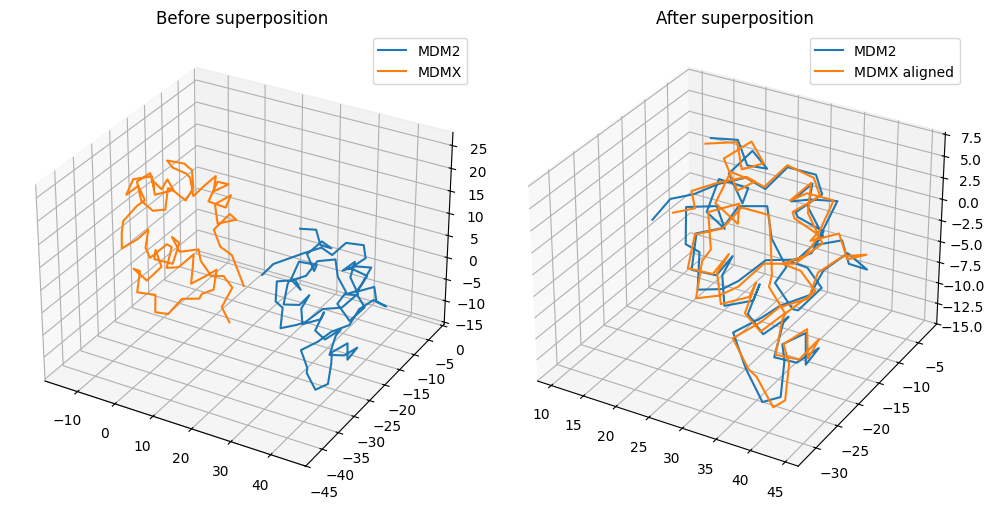

In [17]:

fixed_coords = np.array([
    atom.coord for atom in mdm2_atoms
])

moving_coords = np.array([
    atom.coord for atom in mdmx_atoms
])

rotation, translation = superimposer.rotran

aligned_coords = moving_coords @ rotation + translation

fig = plt.figure(figsize=(10, 5))

ax1 = fig.add_subplot(121, projection="3d")

ax1.plot(
    fixed_coords[:, 0],
    fixed_coords[:, 1],
    fixed_coords[:, 2],
    label="MDM2"
)

ax1.plot(
    moving_coords[:, 0],
    moving_coords[:, 1],
    moving_coords[:, 2],
    label="MDMX"
)

ax1.set_title("Before superposition")
ax1.legend()

ax2 = fig.add_subplot(122, projection="3d")

ax2.plot(
    fixed_coords[:, 0],
    fixed_coords[:, 1],
    fixed_coords[:, 2],
    label="MDM2"
)

ax2.plot(
    aligned_coords[:, 0],
    aligned_coords[:, 1],
    aligned_coords[:, 2],
    label="MDMX aligned"
)

ax2.set_title("After superposition")
ax2.legend()

plt.tight_layout()

plt.savefig(
    results_folder / "MDM2_MDMX_alignment.png",
    dpi=300
)

plt.show()


In [18]:

assert len(mdm2_atoms) == len(mdmx_atoms)

assert np.isfinite(superimposer.rms)

assert superimposer.rms >= 0

assert len(comparison_df) > 0

print("All structural comparison checks passed.")


All structural comparison checks passed.


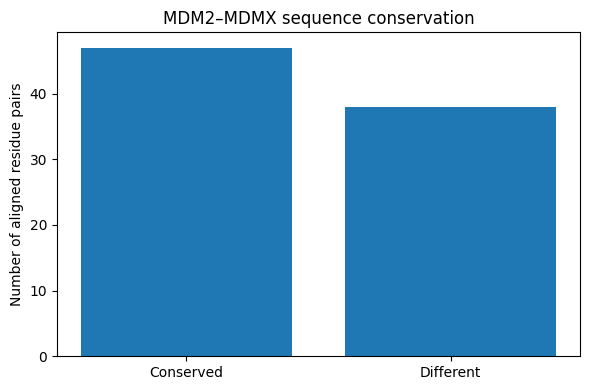

In [19]:

counts = comparison_df["Conserved"].value_counts()

labels = ["Conserved", "Different"]

values = [
    int(counts.get(True, 0)),
    int(counts.get(False, 0))
]

plt.figure(figsize=(6, 4))

plt.bar(labels, values)

plt.ylabel("Number of aligned residue pairs")
plt.title("MDM2–MDMX sequence conservation")

plt.tight_layout()

plt.savefig(
    results_folder / "MDM2_MDMX_conservation.png",
    dpi=300
)

plt.show()
